In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(context='notebook', style='darkgrid', font='sans-serif')

In [5]:
train_df = pd.read_csv('../files/cars_train.csv')
test_df = pd.read_csv('../files/cars_test.csv')

In [10]:
print(f"Train Data size -> {train_df.shape}")
print(f"Test Data size -> {test_df.shape}")

Train Data size -> (1500, 14)
Test Data size -> (500, 14)


In [9]:
train_df.head()

,car_id,brand,model_year,mileage_km,engine_size_l,horsepower,fuel_type,transmission,body_type,condition,owners_count,accidents_reported,fuel_consumption_l,price_usd
0,CAR_00001,Hyundai,2016,214700,1.5,102,Petrol,Automatic,Sedan,Very Good,1,1,5.9,4100
1,CAR_00002,Audi,2015,195600,2.5,192,Petrol,Automatic,Sedan,Good,1,0,7.4,19300
2,CAR_00003,Honda,2023,44800,1.6,126,Petrol,Automatic,Crossover,Very Good,2,1,4.8,15600
3,CAR_00004,Toyota,2015,203400,1.6,116,Petrol,Manual,Sedan,Good,1,0,4.5,4900
4,CAR_00005,Chevrolet,2016,150400,1.4,94,Petrol,Manual,SUV,Very Good,2,1,4.5,2700


In [8]:
train_df.tail()

,car_id,brand,model_year,mileage_km,engine_size_l,horsepower,fuel_type,transmission,body_type,condition,owners_count,accidents_reported,fuel_consumption_l,price_usd
1495,CAR_01496,Toyota,2015,215600,1.5,103,Petrol,Automatic,SUV,Very Good,1,0,4.7,5200
1496,CAR_01497,Toyota,2023,62400,1.5,103,Petrol,Manual,Hatchback,Good,1,2,5.2,9200
1497,CAR_01498,Kia,2023,74900,1.2,88,Petrol,Manual,SUV,Good,1,0,4.5,6900
1498,CAR_01499,Hyundai,2014,189200,1.6,125,Petrol,Automatic,Sedan,Good,1,0,5.7,4600
1499,CAR_01500,BMW,2021,61500,4.0,317,Petrol,Manual,Sedan,Good,2,0,11.6,45000


In [11]:
print(f"Train Data Types -> \n{train_df.dtypes}")

Train Data Types -> 
car_id                    str
brand                     str
model_year              int64
mileage_km              int64
engine_size_l         float64
horsepower              int64
fuel_type                 str
transmission              str
body_type                 str
condition                 str
owners_count            int64
accidents_reported      int64
fuel_consumption_l    float64
price_usd               int64
dtype: object


In [12]:
print(train_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   car_id              1500 non-null   str    
 1   brand               1500 non-null   str    
 2   model_year          1500 non-null   int64  
 3   mileage_km          1500 non-null   int64  
 4   engine_size_l       1500 non-null   float64
 5   horsepower          1500 non-null   int64  
 6   fuel_type           1500 non-null   str    
 7   transmission        1500 non-null   str    
 8   body_type           1500 non-null   str    
 9   condition           1500 non-null   str    
 10  owners_count        1500 non-null   int64  
 11  accidents_reported  1500 non-null   int64  
 12  fuel_consumption_l  1500 non-null   float64
 13  price_usd           1500 non-null   int64  
dtypes: float64(2), int64(6), str(6)
memory usage: 164.2 KB
None


In [13]:
print(f"Nulls count -> {train_df.isnull().sum().sum()}")

Nulls count -> 0


In [14]:
print(train_df.describe())

        model_year     mileage_km  engine_size_l   horsepower  owners_count  \
count  1500.000000    1500.000000    1500.000000  1500.000000   1500.000000   
mean   2018.333333  131080.666667       1.860000   136.231333      1.859333   
std       3.972330   72314.901850       0.648084    57.919216      0.903377   
min    2010.000000   10200.000000       1.200000    75.000000      1.000000   
25%    2015.000000   74825.000000       1.500000   100.000000      1.000000   
50%    2019.000000  120200.000000       1.600000   113.000000      2.000000   
75%    2022.000000  176825.000000       2.000000   150.000000      2.000000   
max    2025.000000  423600.000000       4.400000   369.000000      4.000000   

       accidents_reported  fuel_consumption_l      price_usd  
count         1500.000000         1500.000000    1500.000000  
mean             0.267333            5.660667   12837.133333  
std              0.544117            2.096036   13666.263777  
min              0.000000           

In [18]:
Q1, Q3 = train_df['price_usd'].quantile([0.25, 0.75])
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = train_df[(train_df['price_usd'] < lower_bound) | (train_df['price_usd'] > upper_bound)]

print(f"Lower bound -> {lower_bound}")
print(f"Upper bound -> {upper_bound}")
print(f"IQR -> {IQR}")
print(f"Outliers count -> {len(outliers)}")

# price usd ni describe bilan korganimizda umumiy manoda outlier yoq desak boladi chunki hammasi mantiqli

Lower bound -> -8600.0
Upper bound -> 27400.0
IQR -> 9000.0
Outliers count -> 184


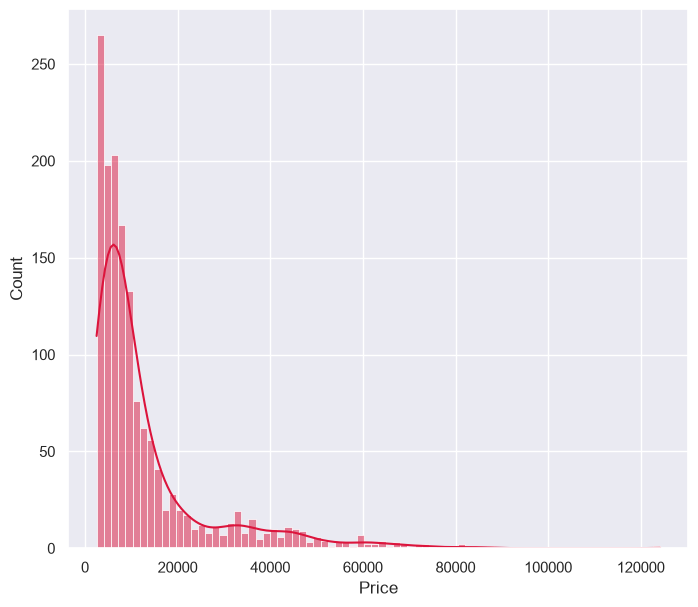

In [22]:
plt.figure(figsize=(8, 7))
sns.histplot(data=train_df, x='price_usd', kde=True, color="crimson" )
plt.xlabel('Price')
plt.show()

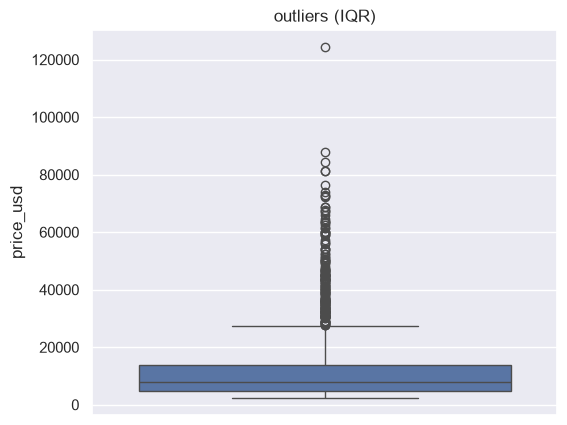

In [25]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=train_df, y='price_usd')
plt.title('outliers (IQR)')
plt.show()
# outlierlar asosan upper bounddan teppadaligini korishimiz mumkin chunki qimmat mashinalar kop

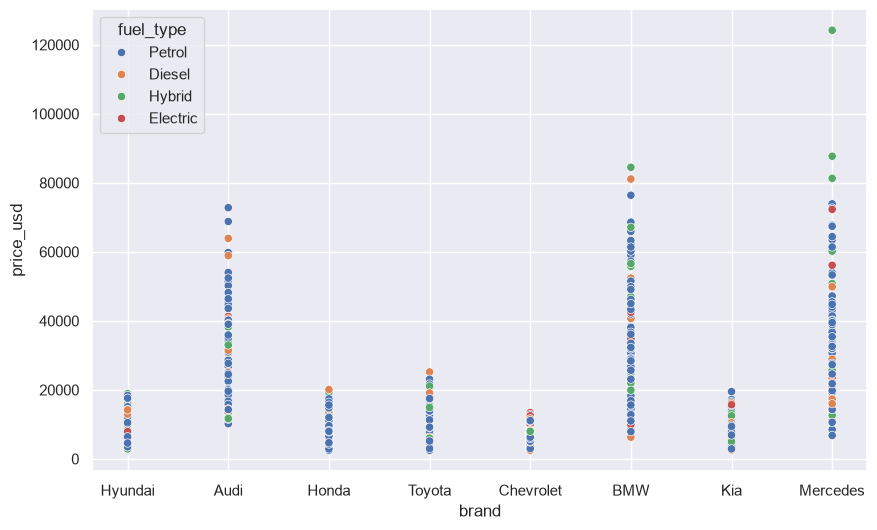

In [28]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train_df, x='brand', y='price_usd', hue='fuel_type')
plt.show()